In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pickle as pkl
import os
import glob
import cartopy as cp
import cartopy.crs as ccrs
from cartopy.util import add_cyclic_point
from matplotlib.colors import ListedColormap, BoundaryNorm
#from plot_ACCLIP_profs import plot_model_overlay, get_ACCLIP_merge_data, get_model_prof_data
import plotter_config as pc
#from get_cbar import get_colorbar
import utils

In [2]:
def draw_box(ax, left, right, bot, top, col, thk):
    ax.plot([left, left], [bot, top], color=col, linewidth=thk)
    ax.plot([right, right], [bot, top], color=col, linewidth=thk)
    ax.plot([left, right], [bot, bot], color=col, linewidth=thk)
    ax.plot([left, right], [top, top], color=col, linewidth=thk)    

In [3]:
def make_map_avg_plot(ax, SAVEDIR, model_name, var, prs_lvl, lev_choice, date0, date1, cbaraxes = [0.13,0.05,0.76,0.02], cb=0, cb_or='horizontal'):

    var_mod = pc.var_info[var]['mod']
    var_lab = pc.var_info[var]['lab']
    unit = pc.var_info[var]['unit']

    with open(SAVEDIR + model_name + '_' + var + '_AvgMap_' + lev_choice + '_' + date0 + '_' + date1 + '.pkl', 'rb') as f:     # PREVIOUSLY MapData (reader v0)
        var_array1, lvls1, lon, lat, date, datesec = pkl.load(f)
    print(np.shape(var_array1))
    p = list(lvls1).index(prs_lvl)
    #var_mean1 = np.nanmean(np.squeeze(var_array1[:,p,:,:]), axis = 0)*var_mod     # From version 0
    var_mean = np.squeeze(var_array1[p,:,:])*pc.var_info[var]['mod']

    cbar_lev, cbar_rgb, norm = utils.get_colorbar(var, prs_lvl, cb)

    var_diff_cyc, lon_cyc = cp.util.add_cyclic_point(var_mean, coord=lon)
    
    print(np.min(var_mean), np.max(var_mean))

    #levels, colormap, norm = get_colorbar(var, prs_lvl, 0)  # Get colorbar information

    ax.set_ylim([-90,90])
    ax.set_xlim([-180,180])
    #ax.set_xlim([0,180])
    #ax.set_ylim([0,60])

    con = ax.contourf(lon_cyc, lat, var_diff_cyc, cmap = cbar_rgb, levels = cbar_lev, norm=norm, extend = 'both', transform=ccrs.PlateCarree())
    ax.coastlines()
    
    plt.title(model_name)
    
    cbaxes = fig.add_axes(cbaraxes)
    cbar = plt.colorbar(con, cax=cbaxes, \
            orientation=cb_or, spacing='uniform',\
            shrink=0.5, extend='both')#, ticks=levels[:-1])  
    cbar.ax.tick_params(labelsize=18)
    cbar.set_label(var + '(' + pc.var_info[var]['unit'] + ')', fontsize=18)


        

    #GV_OBSROOT = '/glade/work/wsmith/ACCLIP_GV_R1_60SEC_Merge/'
    #GV_FLT_DATES = ['20220730','20220804','20220806','20220807','20220812','20220815','20220816','20220819','20220822','20220823','20220825','20220826','20220829','20220830']
    #ACCLIP_GV_lon = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLON') 
    #ACCLIP_GV_lat = get_ACCLIP_merge_data(GV_OBSROOT, GV_FLT_DATES, 'GGLAT')     

    #WB_OBSROOT = '/glade/work/wsmith/ACCLIP_WB57_R1_60SEC_Merge/'
    #WB_FLT_DATES = ['20220802','20220804','20220806','20220812','20220813','20220815','20220816','20220819','20220821','20220823','20220825','20220826','20220829','20220831','20220901']
    #ACCLIP_WB_lon = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LONG_MMS') 
    #ACCLIP_WB_lat = get_ACCLIP_merge_data(WB_OBSROOT, WB_FLT_DATES, 'G_LAT_MMS') 

    #ax.scatter(ACCLIP_GV_lon, ACCLIP_GV_lat, s=0.1, color='black')
    #ax.scatter(ACCLIP_WB_lon, ACCLIP_WB_lat, s=0.1, color='gray')

    #draw_box(ax, 125, 140, 25, 38, 'magenta', 2)
    #draw_box(ax, 95, 125, 30, 45, 'magenta', 2)
    

In [4]:

SAVEDIR = '/glade/u/home/wsmith/NudgeComparison_scripts/vars/'

model_names = ['2022_M2-weak_h0','2022_M2-strong_h0','2022_E5-weak_h0','2022_E5-strong_h0','2022_FreeRun_h0']

var_str = 'CO'

date0 = '2022-05'  # Presumably this is what you need to work with the monthly files
date1 = '2022-09'


(7, 192, 288)
13.608992508955213 63.844284196083095
(7, 192, 288)
14.029626816391504 65.85267157270049
(7, 192, 288)
13.878795546115892 61.635564540130524
(7, 192, 288)
14.640088674130165 61.962244915651624
(7, 192, 288)
13.323738265630245 65.18944900649082


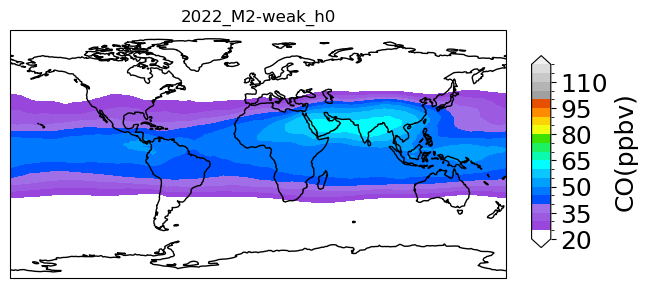

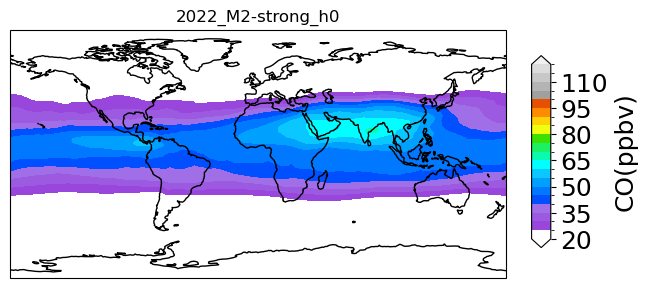

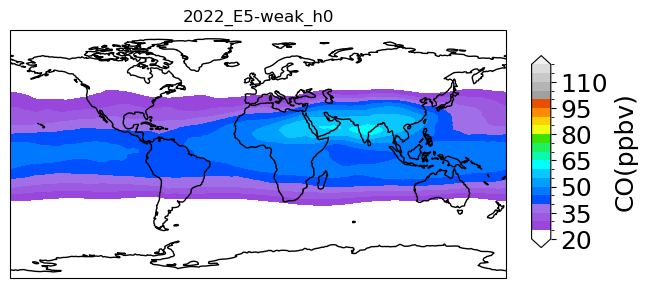

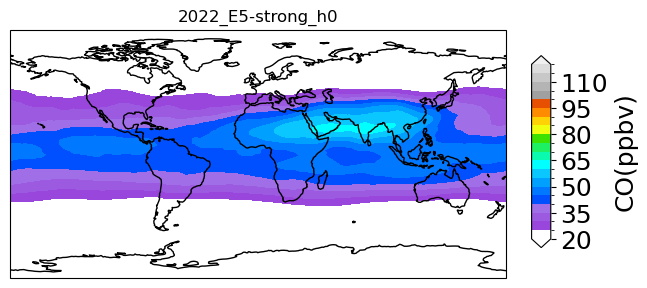

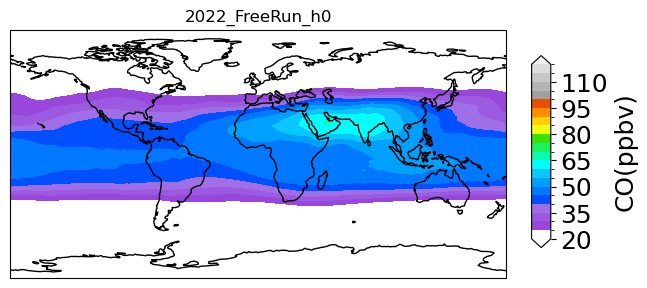

In [5]:

for model_name in model_names: 

    fig = plt.figure()
    ax1 = fig.add_subplot(111, projection = ccrs.PlateCarree())

    #ax4 = fig.add_subplot(224, projection = ccrs.PlateCarree())

    make_map_avg_plot(ax1, SAVEDIR, model_name, var_str, 100., 'plev', date0, date1, cbaraxes = [0.94,0.3,0.03,0.4], cb_or='vertical')
    
    #plt.figtext(0.6,0.66,'850 hPa', fontsize=12, fontweight='bold')


(1, 192, 288)
0.0 5.7820077
(1, 192, 288)
0.0 7.5516405
(1, 192, 288)
0.0 5.1331377
(1, 192, 288)
0.0 6.577268
(1, 192, 288)
0.0 3.4798567


TypeError: 'GeometryCollection' object is not subscriptable

Error in callback <function _draw_all_if_interactive at 0x1487999ba700> (for post_execute), with arguments args (),kwargs {}:


TypeError: 'GeometryCollection' object is not subscriptable

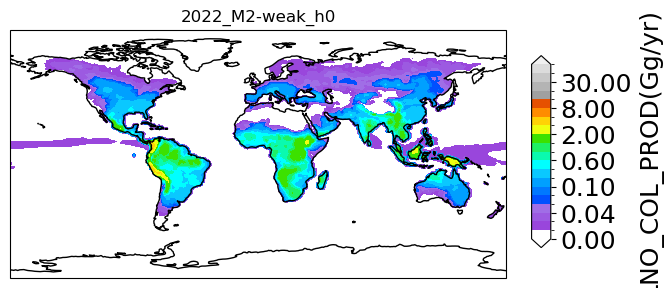

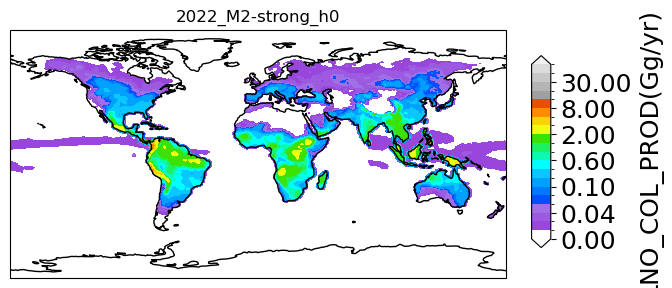

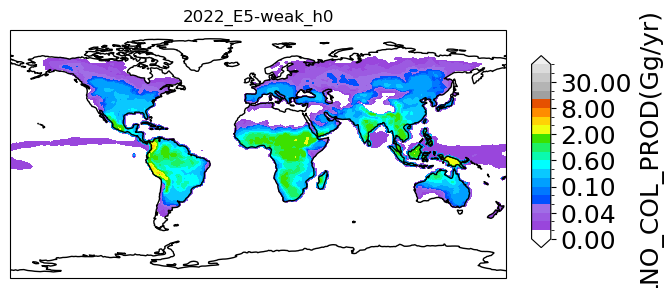

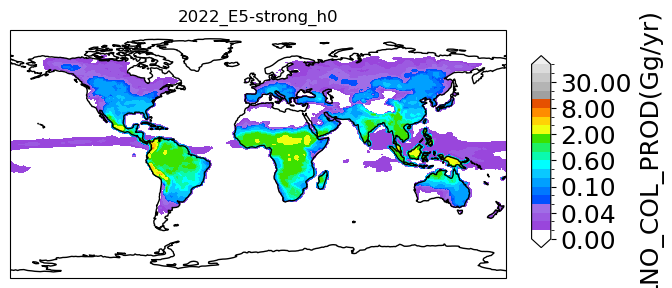

TypeError: 'GeometryCollection' object is not subscriptable

<Figure size 640x480 with 1 Axes>

In [6]:

SAVEDIR = '/glade/u/home/wsmith/NudgeComparison_scripts/vars/'

var_str = 'LNO_COL_PROD'

date0 = '2022-01'  # Presumably this is what you need to work with the monthly files
date1 = '2022-12'

for model_name in model_names: 

    fig = plt.figure()
    ax1 = fig.add_subplot(111, projection = ccrs.PlateCarree())

    #ax4 = fig.add_subplot(224, projection = ccrs.PlateCarree())

    make_map_avg_plot(ax1, SAVEDIR, model_name, var_str, 0., 'plev', date0, date1, cbaraxes = [0.94,0.3,0.03,0.4], cb_or='vertical', cb=0)
    
    #plt.figtext(0.6,0.66,'850 hPa', fontsize=12, fontweight='bold')

